# Predicción de abandono de clientes (Churn) — Telco

**Objetivo:** construir un *pipeline* de scikit-learn que prediga si un cliente de una empresa de telecomunicaciones **abandonará el servicio** (`Churn = Yes`).

**Dataset:** *Telco Customer Churn* (IBM / Kaggle) — 7,043 clientes, 20 variables (demográficas, servicios contratados, facturación). Archivo: `data/telco_churn.csv`.

**Contenido**
1. Carga y exploración (EDA)
2. Limpieza y partición train/test
3. Feature Engineering (transformador propio dentro del pipeline)
4. Pipeline de preprocesamiento + modelo
5. Comparación de modelos con Cross Validation
6. Optimización con GridSearchCV
7. Ajuste del umbral de decisión
8. **Evaluación final** en el conjunto de prueba
9. Interpretabilidad
10. Exportación del pipeline a `.pkl` y prueba de carga

**Métrica principal:** ROC-AUC (clases desbalanceadas, ~27% churn) y F1 / Recall de la clase *Churn*, porque lo costoso para el negocio es no detectar a quien se va.

In [1]:
import warnings, joblib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score,
                             RocCurveDisplay, PrecisionRecallDisplay, f1_score, precision_score, recall_score,
                             accuracy_score, precision_recall_curve, average_precision_score)
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid", palette="deep")
RANDOM_STATE = 42

## 1. Carga y exploración de datos

In [2]:
df = pd.read_csv("data/telco_churn.csv")
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

`TotalCharges` aparece como `object` aunque es numérica: seguramente trae espacios en blanco. Lo verificamos.

In [4]:
mask = pd.to_numeric(df["TotalCharges"], errors="coerce").isna()
print("Filas con TotalCharges no numérico:", mask.sum())
df.loc[mask, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Filas con TotalCharges no numérico: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


Son clientes con `tenure = 0` (recién dados de alta, aún sin facturar); el valor faltante realmente significa **0 cargos acumulados**.

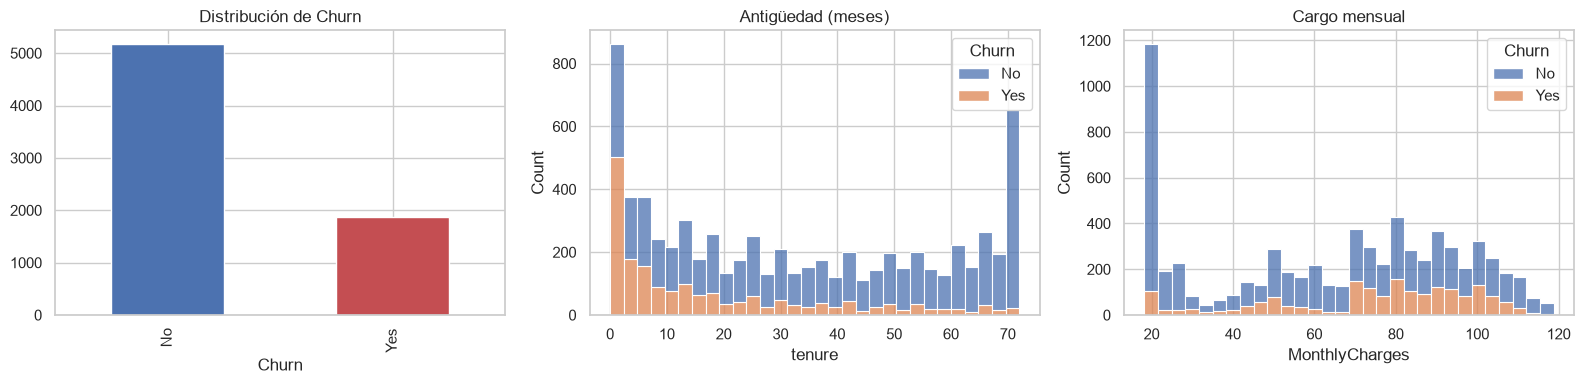

Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
df["Churn"].value_counts().plot.bar(ax=ax[0], color=["#4C72B0", "#C44E52"]); ax[0].set_title("Distribución de Churn")
sns.histplot(data=df, x="tenure", hue="Churn", bins=30, ax=ax[1], multiple="stack"); ax[1].set_title("Antigüedad (meses)")
sns.histplot(data=df, x="MonthlyCharges", hue="Churn", bins=30, ax=ax[2], multiple="stack"); ax[2].set_title("Cargo mensual")
plt.tight_layout(); plt.show()
print(df["Churn"].value_counts(normalize=True).round(3))

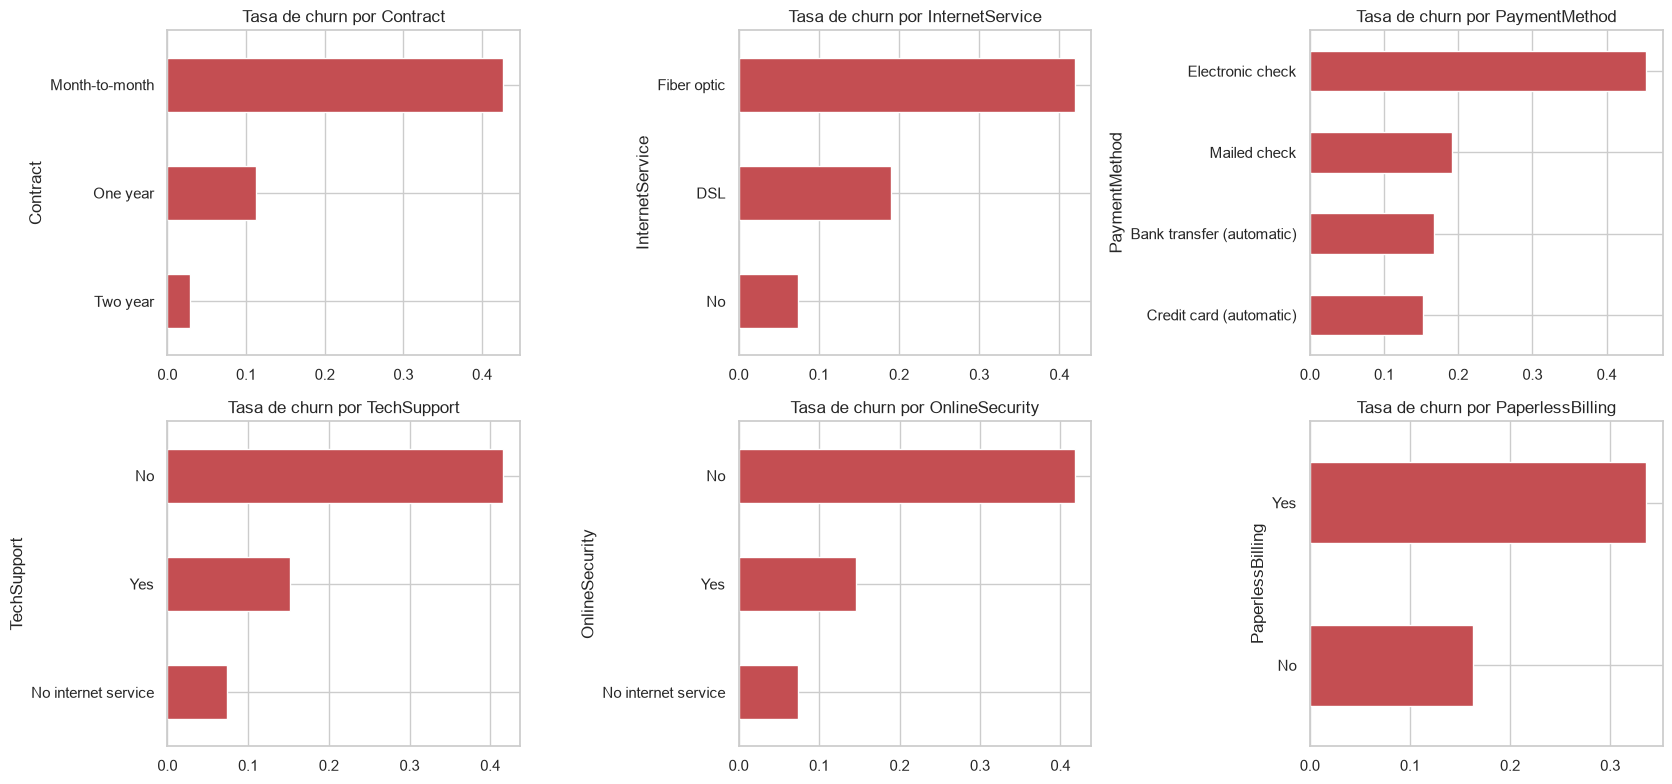

In [6]:
cats = ["Contract", "InternetService", "PaymentMethod", "TechSupport", "OnlineSecurity", "PaperlessBilling"]
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for a, c in zip(axes.ravel(), cats):
    rate = df.groupby(c)["Churn"].apply(lambda s: (s == "Yes").mean()).sort_values()
    rate.plot.barh(ax=a, color="#C44E52"); a.set_title(f"Tasa de churn por {c}"); a.set_xlabel("")
plt.tight_layout(); plt.show()

**Hallazgos del EDA**
- Clases desbalanceadas (~26.5% churn) → usaremos validación estratificada y métricas distintas de *accuracy*.
- El churn se concentra en clientes **nuevos** (poca antigüedad), con contrato **mes a mes**, **fibra óptica**, pago con **cheque electrónico** y **sin soporte técnico / seguridad en línea**.
- Esto motiva variables derivadas: grupos de antigüedad, número de servicios contratados, cargo promedio histórico, etc.

## 2. Limpieza y partición train/test

In [7]:
df = df.drop(columns="customerID")                        # identificador, sin valor predictivo
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df.loc[df["tenure"] == 0, "TotalCharges"] = 0.0           # sin facturar aún = 0
y = (df.pop("Churn") == "Yes").astype(int)
X = df

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape, "| churn train/test:", y_train.mean().round(3), y_test.mean().round(3))
print("Nulos restantes:", X.isna().sum().sum(), "| duplicados:", X.duplicated().sum())

(5634, 19) (1409, 19) | churn train/test: 0.265 0.265
Nulos restantes: 0 | duplicados: 40


El conjunto de prueba se aparta **ahora** y no se toca hasta la evaluación final, para evitar *data leakage*. Todo el ajuste (imputación, escalado, codificación, búsqueda de hiperparámetros) usa solo `X_train` mediante validación cruzada.

## 3. Feature Engineering

Se implementa como un transformador de scikit-learn (`ChurnFeatureEngineer`) para que **forme parte del pipeline** y se aplique igual en entrenamiento y en producción. Se guarda en `churn_features.py` porque `pickle` necesita poder importar la clase al cargar el modelo.

Variables nuevas:
| Variable | Idea |
|---|---|
| `n_services` | cantidad de servicios adicionales contratados (más servicios → más vinculación) |
| `has_internet`, `has_phone_only` | tipo de cliente |
| `avg_monthly_charge` | `TotalCharges / tenure` (gasto promedio real) |
| `charge_diff` | cargo actual − promedio histórico (¿le subieron el precio?) |
| `tenure_group` | rangos de antigüedad (0-12, 13-24, 25-48, 49+) |
| `is_autopay` | pago automático (tarjeta/transferencia) |
| `no_protection` | internet sin seguridad ni soporte técnico |
| `monthly_contract` | contrato mes a mes |

In [8]:
%%writefile churn_features.py
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin

SERVICE_COLS = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
                "TechSupport", "StreamingTV", "StreamingMovies"]


class ChurnFeatureEngineer(BaseEstimator, TransformerMixin):
    """Limpia TotalCharges y crea variables derivadas para el dataset Telco Churn."""

    def fit(self, X, y=None):
        self.feature_names_in_ = np.array(X.columns)
        return self

    def transform(self, X):
        X = X.copy()
        # TotalCharges viene como texto con espacios en blanco para clientes nuevos
        X["TotalCharges"] = pd.to_numeric(X["TotalCharges"], errors="coerce")
        X.loc[X["tenure"] == 0, "TotalCharges"] = 0.0

        X["n_services"] = sum((X[c] == "Yes").astype(int) for c in SERVICE_COLS)
        X["has_internet"] = (X["InternetService"] != "No").astype(int)
        X["has_phone_only"] = ((X["InternetService"] == "No") & (X["PhoneService"] == "Yes")).astype(int)
        X["avg_monthly_charge"] = np.where(X["tenure"] > 0, X["TotalCharges"] / X["tenure"].replace(0, 1), X["MonthlyCharges"])
        X["charge_diff"] = X["MonthlyCharges"] - X["avg_monthly_charge"]
        X["tenure_group"] = pd.cut(X["tenure"], bins=[-1, 12, 24, 48, np.inf],
                                   labels=["0-12", "13-24", "25-48", "49+"]).astype(str)
        X["is_autopay"] = X["PaymentMethod"].str.contains("automatic", case=False, na=False).astype(int)
        X["no_protection"] = ((X["InternetService"] != "No") &
                              (X["OnlineSecurity"] != "Yes") & (X["TechSupport"] != "Yes")).astype(int)
        X["monthly_contract"] = (X["Contract"] == "Month-to-month").astype(int)
        return X

Overwriting churn_features.py


In [9]:
from churn_features import ChurnFeatureEngineer
fe = ChurnFeatureEngineer()
X_fe = fe.fit_transform(X_train)
new_cols = [c for c in X_fe.columns if c not in X_train.columns]
print("Variables nuevas:", new_cols)
X_fe[new_cols].assign(Churn=y_train.values).groupby("Churn").mean(numeric_only=True).T.round(2)

Variables nuevas: ['n_services', 'has_internet', 'has_phone_only', 'avg_monthly_charge', 'charge_diff', 'tenure_group', 'is_autopay', 'no_protection', 'monthly_contract']


Churn,0,1
n_services,2.15,1.80
has_internet,0.73,0.94
has_phone_only,0.27,0.06
avg_monthly_charge,61.36,74.86
charge_diff,-0.01,0.00
is_autopay,0.50,0.26
no_protection,0.25,0.67
monthly_contract,0.43,0.89


Las variables nuevas ya separan a los clientes que se van de los que se quedan (p. ej. menos servicios, más contratos mensuales, menor autopago).

## 4. Pipeline de preprocesamiento + modelo

`Pipeline = ChurnFeatureEngineer → ColumnTransformer(numéricas: imputar+escalar | categóricas: imputar+One-Hot) → clasificador`

In [10]:
num_features = ["tenure", "MonthlyCharges", "TotalCharges", "n_services", "avg_monthly_charge", "charge_diff", "SeniorCitizen",
                "has_internet", "has_phone_only", "is_autopay", "no_protection", "monthly_contract"]
cat_features = [c for c in X_fe.columns if c not in num_features]
print("Categóricas:", cat_features)

preprocess = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), num_features),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_features),
])

def make_pipeline(clf):
    return Pipeline([("features", ChurnFeatureEngineer()), ("preprocess", preprocess), ("clf", clf)])

Categóricas: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'tenure_group']


## 5. Comparación de modelos con Cross Validation

Validación cruzada estratificada de 5 folds sobre el conjunto de entrenamiento. `class_weight="balanced"` compensa el desbalance. Se incluye un *baseline* (`Dummy`) como referencia mínima.

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
models = {
    "Dummy (baseline)":     DummyClassifier(strategy="stratified", random_state=RANDOM_STATE),
    "Regresión Logística":  LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Random Forest":        RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
    "HistGradientBoosting": HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE),
}
rows = []
for name, clf in models.items():
    pipe = make_pipeline(clf)
    auc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    f1  = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1", n_jobs=-1)
    rows.append({"Modelo": name, "ROC-AUC": auc.mean(), "± AUC": auc.std(), "F1 (churn)": f1.mean(), "± F1": f1.std()})
cv_results = pd.DataFrame(rows).set_index("Modelo").round(4).sort_values("ROC-AUC", ascending=False)
cv_results

,ROC-AUC,± AUC,F1 (churn),± F1
Modelo,,,,
Regresión Logística,0.8456,0.0118,0.6253,0.0246
HistGradientBoosting,0.8356,0.0087,0.6189,0.0162
Random Forest,0.8290,0.0094,0.6123,0.0266
Dummy (baseline),0.5065,0.0171,0.2762,0.0249


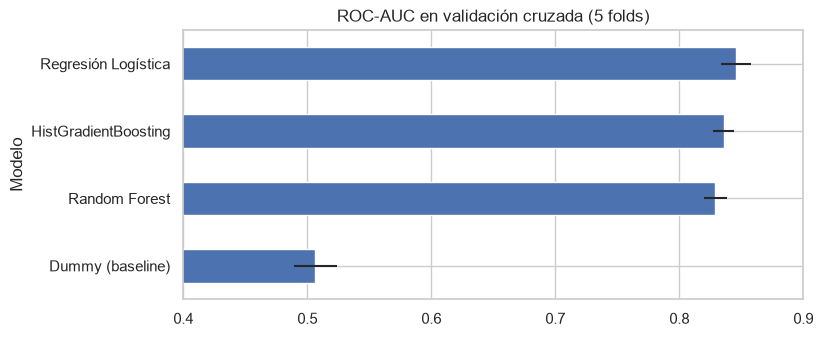

In [12]:
ax = cv_results["ROC-AUC"].sort_values().plot.barh(xerr=cv_results["± AUC"], color="#4C72B0", figsize=(8, 3.5))
ax.set_xlim(0.4, 0.9); ax.set_title("ROC-AUC en validación cruzada (5 folds)"); plt.show()

## 6. Optimización de hiperparámetros con GridSearchCV

Se afinan los dos mejores candidatos (Regresión Logística y HistGradientBoosting) optimizando **ROC-AUC** con el mismo esquema de CV. Los nombres de los parámetros usan el prefijo `clf__` del pipeline, así la búsqueda evalúa el pipeline completo (sin fuga de datos entre folds).

In [13]:
grids = {
    "Regresión Logística": (LogisticRegression(max_iter=3000, class_weight="balanced"),
        {"clf__C": [0.01, 0.05, 0.1, 0.5, 1, 5], "clf__penalty": ["l1", "l2"], "clf__solver": ["liblinear"]}),
    "HistGradientBoosting": (HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE),
        {"clf__learning_rate": [0.03, 0.05, 0.1], "clf__max_depth": [2, 3, 5],
         "clf__max_leaf_nodes": [8, 15], "clf__l2_regularization": [0.0, 1.0, 5.0], "clf__min_samples_leaf": [20, 50]}),
}
searches = {}
for name, (clf, grid) in grids.items():
    gs = GridSearchCV(make_pipeline(clf), grid, cv=cv, scoring="roc_auc", n_jobs=-1, refit=True)
    gs.fit(X_train, y_train)
    searches[name] = gs
    print(f"{name:22s} mejor AUC CV = {gs.best_score_:.4f} | {gs.best_params_}")

Regresión Logística    mejor AUC CV = 0.8457 | {'clf__C': 5, 'clf__penalty': 'l2', 'clf__solver': 'liblinear'}


HistGradientBoosting   mejor AUC CV = 0.8497 | {'clf__l2_regularization': 5.0, 'clf__learning_rate': 0.1, 'clf__max_depth': 2, 'clf__max_leaf_nodes': 8, 'clf__min_samples_leaf': 50}


In [14]:
best_name = max(searches, key=lambda k: searches[k].best_score_)
best_search = searches[best_name]
print("Modelo ganador:", best_name, "| AUC CV:", round(best_search.best_score_, 4))

Modelo ganador: HistGradientBoosting | AUC CV: 0.8497


## 7. Ajuste del umbral de decisión

Con el umbral por defecto (0.5) no necesariamente se maximiza el F1 de la clase *Churn*. Para elegirlo **sin tocar el test**, usamos predicciones *out-of-fold* del mejor pipeline sobre el conjunto de entrenamiento.

Umbral óptimo (máx. F1 en OOF): 0.555  | F1 OOF = 0.642  (con 0.5: 0.633)


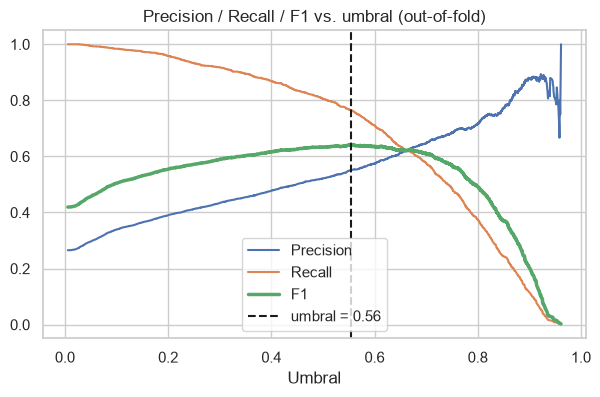

In [15]:
best_pipe = best_search.best_estimator_
oof_proba = cross_val_predict(best_pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof_proba)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-9)
best_thr = float(thr[np.argmax(f1s)])
print(f"Umbral óptimo (máx. F1 en OOF): {best_thr:.3f}  | F1 OOF = {f1s.max():.3f}  (con 0.5: {f1_score(y_train, oof_proba>=0.5):.3f})")

plt.figure(figsize=(7, 4))
plt.plot(thr, prec[:-1], label="Precision"); plt.plot(thr, rec[:-1], label="Recall"); plt.plot(thr, f1s, label="F1", lw=2.5)
plt.axvline(best_thr, color="k", ls="--", label=f"umbral = {best_thr:.2f}")
plt.xlabel("Umbral"); plt.legend(); plt.title("Precision / Recall / F1 vs. umbral (out-of-fold)"); plt.show()

## 8. Evaluación final en el conjunto de prueba

Primera y única vez que se usa `X_test`. Se empaqueta el pipeline ganador junto con el umbral elegido en un envoltorio (`ChurnModel`) para que `predict` aplique el umbral optimizado.

In [16]:
y_proba = best_pipe.predict_proba(X_test)[:, 1]
y_pred_default = (y_proba >= 0.5).astype(int)
y_pred = (y_proba >= best_thr).astype(int)

def metrics(y_true, pred, proba):
    return {"Accuracy": accuracy_score(y_true, pred), "Precision": precision_score(y_true, pred),
            "Recall": recall_score(y_true, pred), "F1": f1_score(y_true, pred),
            "ROC-AUC": roc_auc_score(y_true, proba), "PR-AUC": average_precision_score(y_true, proba)}

dummy = make_pipeline(DummyClassifier(strategy="stratified", random_state=RANDOM_STATE)).fit(X_train, y_train)
dproba = dummy.predict_proba(X_test)[:, 1]
final = pd.DataFrame({
    "Baseline (Dummy)": metrics(y_test, dummy.predict(X_test), dproba),
    "Modelo (umbral 0.5)": metrics(y_test, y_pred_default, y_proba),
    f"Modelo (umbral {best_thr:.2f})": metrics(y_test, y_pred, y_proba),
}).T.round(4)
final

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Baseline (Dummy),0.6217,0.2891,0.2914,0.2903,0.5163,0.2723
Modelo (umbral 0.5),0.7452,0.5128,0.8048,0.6264,0.8453,0.6623
Modelo (umbral 0.56),0.7651,0.5406,0.7647,0.6334,0.8453,0.6623


In [17]:
print(classification_report(y_test, y_pred, target_names=["Se queda", "Churn"], digits=3))

              precision    recall  f1-score   support

    Se queda      0.900     0.765     0.827      1035
       Churn      0.541     0.765     0.633       374

    accuracy                          0.765      1409
   macro avg      0.720     0.765     0.730      1409
weighted avg      0.805     0.765     0.776      1409



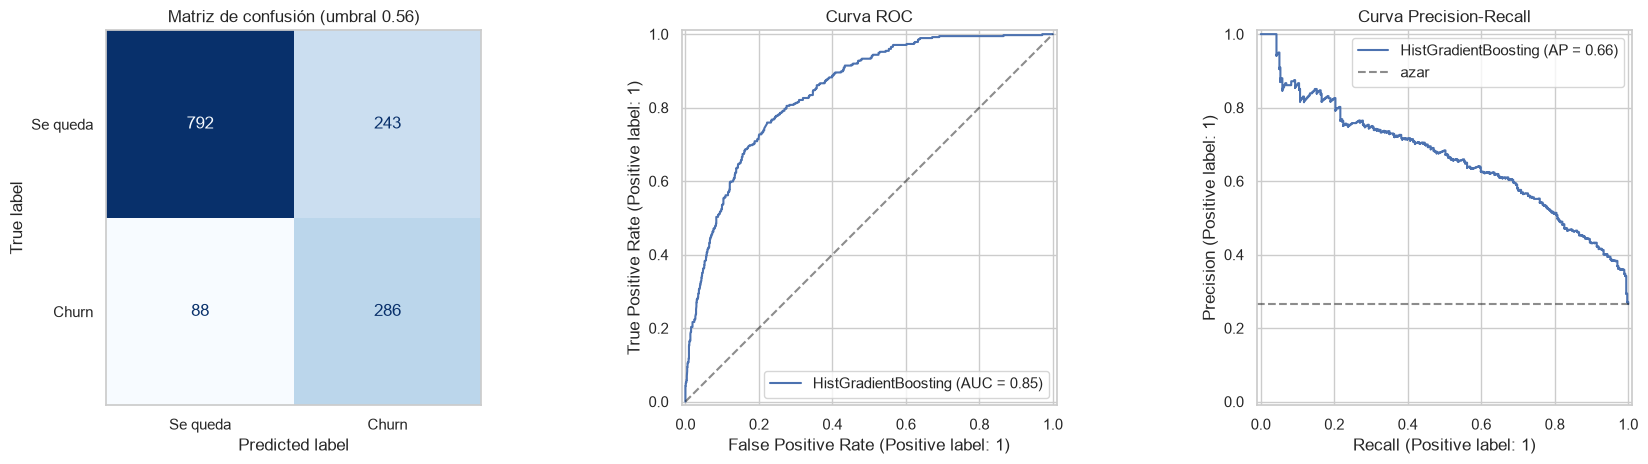

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Se queda", "Churn"], cmap="Blues", ax=ax[0], colorbar=False)
ax[0].set_title(f"Matriz de confusión (umbral {best_thr:.2f})"); ax[0].grid(False)
RocCurveDisplay.from_predictions(y_test, y_proba, ax=ax[1], name=best_name); ax[1].plot([0,1],[0,1],"k--",alpha=.5); ax[1].set_title("Curva ROC")
PrecisionRecallDisplay.from_predictions(y_test, y_proba, ax=ax[2], name=best_name)
ax[2].axhline(y_test.mean(), color="k", ls="--", alpha=.5, label="azar"); ax[2].legend(); ax[2].set_title("Curva Precision-Recall")
plt.tight_layout(); plt.show()

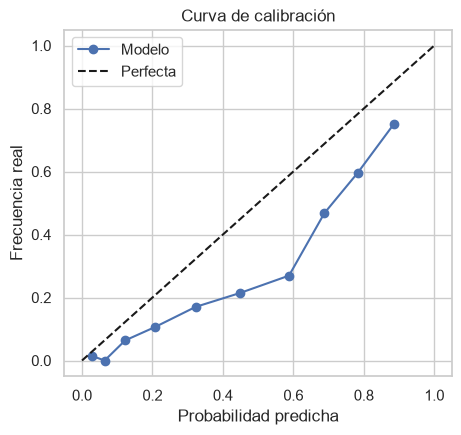

ROC-AUC test = 0.8453  (IC 95% bootstrap: 0.8235 – 0.8668)


In [19]:
# Calibración: ¿la probabilidad predicha coincide con la frecuencia real de churn?
from sklearn.calibration import calibration_curve
frac_pos, mean_pred = calibration_curve(y_test, y_proba, n_bins=10, strategy="quantile")
plt.figure(figsize=(5, 4.5)); plt.plot(mean_pred, frac_pos, "o-", label="Modelo"); plt.plot([0,1],[0,1],"k--", label="Perfecta")
plt.xlabel("Probabilidad predicha"); plt.ylabel("Frecuencia real"); plt.title("Curva de calibración"); plt.legend(); plt.show()

# Estabilidad: intervalo de confianza bootstrap del AUC en test
rng = np.random.default_rng(RANDOM_STATE); yt = y_test.values; aucs = []
for _ in range(1000):
    idx = rng.integers(0, len(yt), len(yt)); aucs.append(roc_auc_score(yt[idx], y_proba[idx]))
print(f"ROC-AUC test = {roc_auc_score(yt, y_proba):.4f}  (IC 95% bootstrap: {np.percentile(aucs,2.5):.4f} – {np.percentile(aucs,97.5):.4f})")

**Lectura de resultados**
- El modelo supera ampliamente al baseline en todas las métricas.
- El umbral óptimo (≈0.56) es ligeramente más alto que 0.5: mejora la **precisión** (0.51→0.54), la accuracy y el F1 a costa de algo de recall (0.80→0.76). Con el umbral de 0.5 se detectan más clientes en riesgo; si el costo de perder un cliente fuese mucho mayor que el de una llamada de retención, convendría bajar el umbral.
- El rendimiento en test es consistente con la validación cruzada (sin sobreajuste evidente) y el intervalo bootstrap muestra que es estable.

## 9. Interpretabilidad

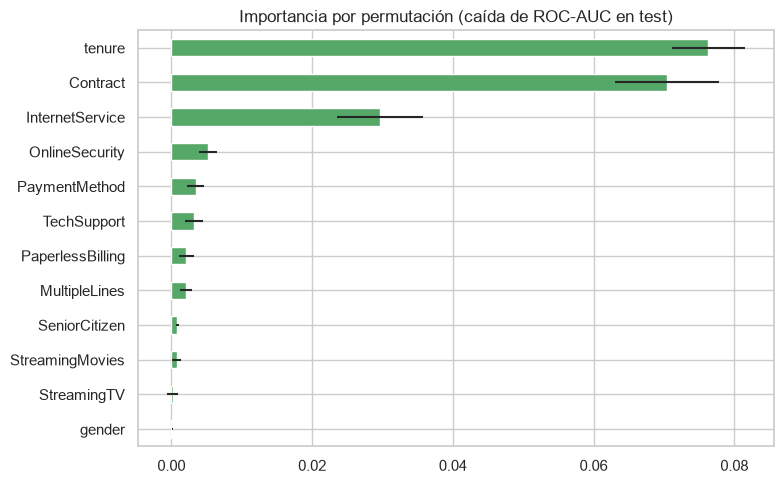

In [20]:
pi = permutation_importance(best_pipe, X_test, y_test, scoring="roc_auc", n_repeats=15, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()
imp.tail(12).plot.barh(xerr=pd.Series(pi.importances_std, index=X_test.columns)[imp.tail(12).index], figsize=(8, 5), color="#55A868")
plt.title("Importancia por permutación (caída de ROC-AUC en test)"); plt.tight_layout(); plt.show()

Las variables que más influyen son las esperables por el EDA: **tipo de contrato, antigüedad, servicio de internet, cargos y servicios de protección/soporte**. Varias de las variables creadas en Feature Engineering aportan señal adicional a las originales.

## 10. Exportación del pipeline a `.pkl`

Se guarda el pipeline completo (feature engineering + preprocesamiento + modelo) junto con el umbral. Quien lo cargue solo necesita pasar un `DataFrame` con las columnas originales del dataset.

In [21]:
%%writefile churn_model.py
import numpy as np
from sklearn.base import BaseEstimator, ClassifierMixin

class ChurnModel(BaseEstimator, ClassifierMixin):
    """Pipeline entrenado + umbral de decisión optimizado."""
    def __init__(self, pipeline=None, threshold=0.5):
        self.pipeline = pipeline
        self.threshold = threshold
        self.classes_ = np.array([0, 1])

    def predict_proba(self, X):
        return self.pipeline.predict_proba(X)

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= self.threshold).astype(int)

Overwriting churn_model.py


In [22]:
from churn_model import ChurnModel
final_model = ChurnModel(pipeline=best_pipe, threshold=best_thr)
joblib.dump(final_model, "churn_pipeline.pkl")

import os; print("Guardado: churn_pipeline.pkl", f"({os.path.getsize('churn_pipeline.pkl')/1024:.0f} KB)")

Guardado: churn_pipeline.pkl (81 KB)


### Verificación: cargar el `.pkl` desde cero y predecir

In [23]:
loaded = joblib.load("churn_pipeline.pkl")
assert np.allclose(loaded.predict_proba(X_test), final_model.predict_proba(X_test)), "las predicciones no coinciden"
assert (loaded.predict(X_test) == y_pred).all()
print("OK — el modelo cargado reproduce exactamente las predicciones.")

# Ejemplo con un cliente nuevo (columnas originales del dataset, sin customerID ni Churn)
nuevo = pd.DataFrame([{
    "gender": "Female", "SeniorCitizen": 0, "Partner": "No", "Dependents": "No", "tenure": 3,
    "PhoneService": "Yes", "MultipleLines": "No", "InternetService": "Fiber optic", "OnlineSecurity": "No",
    "OnlineBackup": "No", "DeviceProtection": "No", "TechSupport": "No", "StreamingTV": "Yes", "StreamingMovies": "Yes",
    "Contract": "Month-to-month", "PaperlessBilling": "Yes", "PaymentMethod": "Electronic check",
    "MonthlyCharges": 89.9, "TotalCharges": "269.7"}])
p = loaded.predict_proba(nuevo)[0, 1]
print(f"Probabilidad de churn: {p:.1%} → {'RIESGO DE ABANDONO' if loaded.predict(nuevo)[0] else 'cliente estable'}")

OK — el modelo cargado reproduce exactamente las predicciones.
Probabilidad de churn: 90.6% → RIESGO DE ABANDONO


## Conclusiones
- Se construyó un pipeline único y reproducible: **feature engineering → preprocesamiento → modelo**, validado con CV estratificada y optimizado con GridSearchCV, sin fuga de datos.
- El umbral de decisión se calibró con predicciones *out-of-fold* y el test se usó una sola vez.
- **Posibles mejoras:** costos asimétricos de negocio para fijar el umbral, SHAP para explicaciones por cliente, probar `XGBoost/LightGBM`, y monitoreo de *drift* en producción.

**Archivos entregables:** `data/telco_churn.csv`, `churn_notebook.ipynb`, `churn_pipeline.pkl` (+ `churn_features.py` y `churn_model.py`, necesarios para cargar el `.pkl`).